# AI-Driven Fraud Detection in Financial Transactions
## Comparative study of ML, DL and XAI techniques + the four-layer hybrid pipeline

This notebook turns the survey paper into runnable code. It covers:

| Section | Paper reference | What the code does |
|---|---|---|
| 1 | Sec. III, Table III | Load the 2013 European cardholder dataset (`creditcard.csv`), or generate a synthetic stand-in with the same shape and ~0.17% fraud rate |
| 2 | Sec. II-A, II-B, Table I | Train the **classical ML** family (LR, RF, KNN, SVM) and the **boosted ensemble** family (XGBoost, LightGBM, CatBoost-style) |
| 3 | Sec. II-E | Compare **class-imbalance handling**: none, class weights, SMOTE, K-means-SMOTE + ENN |
| 4 | Sec. II-B, II-F | **Deep learning** baselines: MLP classifier and an **autoencoder** anomaly detector (reconstruction error) |
| 5 | Sec. II-D, IV-B, Fig. 2 | **Explainable AI**: SHAP and LIME on the boosted model, with per-prediction explanation latency measured |
| 6 | Sec. II-C | **Relational / graph check**: build an entity graph (account, device, merchant) and score ring connectivity |
| 7 | Sec. V, Fig. 3, Table II | Assemble the **four-layer hybrid pipeline**: pre-filter, calibrated ensemble, graph escalation, native reason codes |
| 7b | Sec. VII, Table V, Fig. 6 | **RAAB** (Relational-Anomaly Augmented Boosting): inject out-of-fold entity-risk and autoencoder novelty features into the scoring model; ablation under a **zero-day protocol** over 3 seeds |
| 8 | Sec. IV, Table I | Reproduce the **comparison framework** (accuracy, AUC, F1, latency, interpretability) |

**Runtime:** CPU only. About 5 minutes on the synthetic fallback (3 of those are the 3-seed RAAB loop; set `N_SEEDS = 1` to shorten); longer on the real dataset.


## 0. Setup

Install once if needed:

```
pip install numpy pandas scikit-learn lightgbm xgboost shap lime imbalanced-learn networkx matplotlib
```


In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             precision_recall_curve)

import lightgbm as lgb
import xgboost as xgb
from imblearn.over_sampling import SMOTE, KMeansSMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
RNG = 42
np.random.seed(RNG)
plt.rcParams["figure.dpi"] = 110
print("numpy", np.__version__, "| pandas", pd.__version__, "| lightgbm", lgb.__version__, "| xgboost", xgb.__version__)


numpy 2.4.4 | pandas 3.0.2 | lightgbm 4.7.0 | xgboost 3.2.0


## 1. Data (Sec. III, Table III)

The survey notes that nearly all reported results use two public datasets: the **2013 European cardholder dataset** (~285k rows, ~0.17% fraud, PCA-anonymised `V1..V28` + `Time`, `Amount`) and **IEEE-CIS**.

Download `creditcard.csv` from Kaggle (`mlg-ulb/creditcardfraud`) and put it next to this notebook. If the file is absent, the cell below generates a synthetic dataset with the **same schema and fraud rate**, so every later cell still runs. Results on synthetic data are for pipeline validation only, not for reporting.


In [2]:
DATA_PATH = "creditcard.csv"

def make_synthetic_creditcard(n=120_000, fraud_rate=0.0017, n_pca=28, seed=RNG):
    """Synthetic stand-in mirroring the 2013 European cardholder schema.
    Fraud rows are drawn from a shifted, wider distribution on a subset of PCA dims,
    with larger and more variable amounts, so the classification task is non-trivial."""
    rs = np.random.RandomState(seed)
    n_fraud = int(n * fraud_rate)
    n_legit = n - n_fraud
    legit = rs.normal(0, 1, size=(n_legit, n_pca))
    fraud = rs.normal(0, 1.5, size=(n_fraud, n_pca))
    shift_dims = rs.choice(n_pca, 10, replace=False)
    fraud[:, shift_dims] += rs.uniform(1.0, 2.2, size=len(shift_dims)) * rs.choice([-1, 1], size=len(shift_dims))
    X = np.vstack([legit, fraud])
    amount = np.concatenate([rs.lognormal(3.0, 1.0, n_legit), rs.lognormal(4.0, 1.4, n_fraud)])
    t = rs.uniform(0, 172_800, n)  # two days in seconds, as in the real dataset
    y = np.concatenate([np.zeros(n_legit), np.ones(n_fraud)]).astype(int)
    df = pd.DataFrame(X, columns=[f"V{i}" for i in range(1, n_pca + 1)])
    df.insert(0, "Time", t)   # not sorted: sorting before the vstack would leak the label through Time
    df["Amount"] = amount
    df["Class"] = y
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    DATA_SOURCE = "2013 European cardholder dataset (real)"
else:
    df = make_synthetic_creditcard()
    DATA_SOURCE = "synthetic stand-in (creditcard.csv not found)"

print("Source:", DATA_SOURCE)
print("Shape:", df.shape)
print(f"Fraud rate: {df['Class'].mean():.4%}  ({df['Class'].sum()} fraud / {len(df)} total)")
df.head()


Source: synthetic stand-in (creditcard.csv not found)
Shape: (120000, 31)
Fraud rate: 0.1700%  (204 fraud / 120000 total)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,129626.909391,-1.975450,1.747266,0.108327,-0.328539,0.118502,2.880578,-2.803890,-0.953046,-2.709635,...,-0.144587,1.487335,1.675368,-0.006939,-0.439656,0.129275,1.614089,2.511644,8.293379,0
1,64071.455539,1.442538,0.340007,0.314970,1.030784,0.112274,0.981218,0.177315,0.793059,0.330451,...,-1.063106,0.394587,1.020849,0.121680,1.518816,-0.913147,-0.619934,0.104694,7.070174,0
2,955.927916,0.536201,-0.062020,0.685288,-0.217094,-1.109834,-1.418158,0.574833,-0.514614,-0.913793,...,-0.945919,-0.118132,-0.054379,0.380941,-2.096206,-0.351346,-1.029929,0.313475,21.388913,0
3,155620.374511,-0.448745,0.017146,-1.112195,0.255429,-1.429962,1.561685,1.701546,-0.663823,0.876998,...,-1.347396,-1.217933,0.242283,-0.210765,-1.545798,-0.295598,-0.746711,0.481557,25.163154,0
4,165041.075619,-0.421239,1.489697,-0.940327,1.559118,-1.929077,1.071070,-0.410622,-0.782265,0.167596,...,-1.344831,-1.251589,-0.031747,-0.331645,2.778742,0.095947,-0.770187,0.183693,38.591048,0


In [3]:
# Train / test split, stratified on the rare class. Scale Time and Amount only; V1..V28 are already PCA outputs.
feature_cols = [c for c in df.columns if c != "Class"]
X = df[feature_cols].copy()
y = df["Class"].values

idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=0.3, stratify=y, random_state=RNG)
X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y[idx_train], y[idx_test]

scaler = StandardScaler().fit(X_train[["Time", "Amount"]])
for part in (X_train, X_test):
    part[["Time", "Amount"]] = scaler.transform(part[["Time", "Amount"]])

X_train, X_test = X_train.values, X_test.values
print("train:", X_train.shape, "fraud:", y_train.sum(), "| test:", X_test.shape, "fraud:", y_test.sum())


train: (84000, 30) fraud: 143 | test: (36000, 30) fraud: 61


In [4]:
# Shared evaluation helper: metrics the surveyed studies report (Sec. III inclusion criterion iii) + inference latency.
RESULTS = []

def evaluate(name, family, model, X_te, y_te, interpretability, proba_fn=None, threshold=0.5, n_latency=500):
    """Score a fitted model and log a row for the comparison framework (Table I)."""
    if proba_fn is None:
        if hasattr(model, "predict_proba"):
            proba_fn = lambda A: model.predict_proba(A)[:, 1]
        else:
            proba_fn = lambda A: model.decision_function(A)
    p = proba_fn(X_te)
    pred = (p >= threshold).astype(int)

    # Per-transaction latency (single-row inference, which is what a payment rail sees)
    idx = np.random.RandomState(0).choice(len(X_te), min(n_latency, len(X_te)), replace=False)
    t0 = time.perf_counter()
    for i in idx:
        proba_fn(X_te[i:i+1])
    lat_ms = (time.perf_counter() - t0) / len(idx) * 1000

    row = dict(model=name, family=family,
               accuracy=accuracy_score(y_te, pred),
               precision=precision_score(y_te, pred, zero_division=0),
               recall=recall_score(y_te, pred, zero_division=0),
               f1=f1_score(y_te, pred, zero_division=0),
               auc_roc=roc_auc_score(y_te, p),
               auc_pr=average_precision_score(y_te, p),
               latency_ms=lat_ms,
               interpretability=interpretability)
    RESULTS.append(row)
    print(f"{name:<28} acc={row['accuracy']:.4f} prec={row['precision']:.3f} rec={row['recall']:.3f} "
          f"f1={row['f1']:.3f} auc={row['auc_roc']:.4f} aucpr={row['auc_pr']:.3f} lat={lat_ms:.2f}ms")
    return p


## 2. Classical ML and boosted ensembles (Sec. II-A, II-B)

Baselines first. The survey's point [2], [7]: a new model that cannot beat a well-tuned random forest on the same data is hard to justify. Class weighting is on for all of them; Section 3 isolates the effect of imbalance handling separately.


In [5]:
classical = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.1),
    "Random Forest":       RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                  n_jobs=-1, random_state=RNG, max_depth=12),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Linear SVM (calib.)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", C=0.5, max_iter=5000), cv=3),
}
interp_classical = {"Logistic Regression": "High (intrinsic)", "Random Forest": "Medium (feature importance)",
                    "KNN (k=5)": "Low", "Linear SVM (calib.)": "Medium (linear weights)"}

for name, m in classical.items():
    t0 = time.time(); m.fit(X_train, y_train)
    evaluate(name, "Classical ML", m, X_test, y_test, interp_classical[name])


Logistic Regression          acc=0.9967 prec=0.333 rec=0.951 f1=0.494 auc=0.9980 aucpr=0.917 lat=0.16ms


Random Forest                acc=0.9989 prec=1.000 rec=0.328 f1=0.494 auc=0.9969 aucpr=0.718 lat=53.83ms


KNN (k=5)                    acc=0.9984 prec=1.000 rec=0.049 f1=0.094 auc=0.6557 aucpr=0.313 lat=4.04ms


Linear SVM (calib.)          acc=0.9997 prec=1.000 rec=0.803 f1=0.891 auc=0.9978 aucpr=0.927 lat=1.31ms


In [6]:
pos_weight = (y_train == 0).sum() / max(1, (y_train == 1).sum())   # cost-sensitive weighting, Sec. II-E

boosted = {
    "XGBoost":  xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                                  colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric="aucpr",
                                  tree_method="hist", n_jobs=-1, random_state=RNG),
    # LightGBM needs regularisation under extreme scale_pos_weight, or leaf values blow up (Zhao et al. [20]
    # address the same instability algorithmically). Cap the weight and bound the per-leaf step.
    "LightGBM": lgb.LGBMClassifier(n_estimators=400, num_leaves=31, learning_rate=0.05, subsample=0.8,
                                   colsample_bytree=0.8, scale_pos_weight=min(pos_weight, 50),
                                   reg_lambda=5.0, min_child_samples=50, max_delta_step=1.0,
                                   n_jobs=-1, random_state=RNG, verbose=-1),
}
# CatBoost is optional; the survey [1] found the choice of boosting library mattered less than the pipeline around it.
try:
    from catboost import CatBoostClassifier
    boosted["CatBoost"] = CatBoostClassifier(iterations=400, depth=6, learning_rate=0.05,
                                             scale_pos_weight=pos_weight, verbose=0, random_seed=RNG)
except ImportError:
    print("catboost not installed; skipping (pip install catboost to include it)")

for name, m in boosted.items():
    m.fit(X_train, y_train)
    evaluate(name, "Boosted ensemble", m, X_test, y_test, "Low-Medium (needs post-hoc XAI)")


catboost not installed; skipping (pip install catboost to include it)


XGBoost                      acc=0.9995 prec=0.939 rec=0.754 f1=0.836 auc=0.9996 aucpr=0.914 lat=0.42ms


LightGBM                     acc=0.9995 prec=0.938 rec=0.738 f1=0.826 auc=0.9989 aucpr=0.912 lat=0.62ms


## 3. Class-imbalance handling (Sec. II-E)

The survey's rough consensus: moderate resampling **plus** a cost-sensitive loss beats resampling alone. This cell isolates the effect on a fixed LightGBM model:

- no handling
- cost-sensitive weighting only (`scale_pos_weight`)
- SMOTE oversampling
- K-means-SMOTE + ENN hybrid (Damanik & Liu [16])

Resampling is applied **inside** the training fold only; the test set is untouched.


In [7]:
def lgbm(weighted):
    return lgb.LGBMClassifier(n_estimators=300, num_leaves=31, learning_rate=0.05,
                              scale_pos_weight=min(pos_weight, 50) if weighted else 1.0,
                              reg_lambda=5.0, min_child_samples=50, max_delta_step=1.0,
                              n_jobs=-1, random_state=RNG, verbose=-1)

# SMOTE variants need k_neighbors <= minority count - 1
k_nb = int(min(5, max(1, y_train.sum() - 1)))

imbalance_strategies = {
    "None":                    ImbPipeline([("clf", lgbm(False))]),
    "Cost-sensitive weights":  ImbPipeline([("clf", lgbm(True))]),
    "SMOTE":                   ImbPipeline([("smote", SMOTE(k_neighbors=k_nb, random_state=RNG)),
                                            ("clf", lgbm(False))]),
    "SMOTE + weights":         ImbPipeline([("smote", SMOTE(k_neighbors=k_nb, sampling_strategy=0.1, random_state=RNG)),
                                            ("clf", lgbm(True))]),
}
# K-means-SMOTE can fail if no cluster is minority-dense enough; fall back to SMOTE+ENN in that case.
try:
    kms = ImbPipeline([("kmsmote", KMeansSMOTE(k_neighbors=k_nb, sampling_strategy=0.1,
                                               cluster_balance_threshold=0.01, random_state=RNG)),
                       ("enn", EditedNearestNeighbours(n_neighbors=3)),
                       ("clf", lgbm(True))])
    kms.fit(X_train, y_train)
    imbalance_strategies["K-means-SMOTE + ENN + weights"] = kms
except Exception as e:
    print("KMeansSMOTE failed (", type(e).__name__, ") - using SMOTE + ENN instead")
    imbalance_strategies["SMOTE + ENN + weights"] = ImbPipeline([
        ("smote", SMOTE(k_neighbors=k_nb, sampling_strategy=0.1, random_state=RNG)),
        ("enn", EditedNearestNeighbours(n_neighbors=3)),
        ("clf", lgbm(True))])

imb_rows = []
for name, pipe in imbalance_strategies.items():
    if not hasattr(pipe, "classes_"):
        pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    imb_rows.append(dict(strategy=name,
                         precision=precision_score(y_test, pred, zero_division=0),
                         recall=recall_score(y_test, pred, zero_division=0),
                         f1=f1_score(y_test, pred, zero_division=0),
                         auc_pr=average_precision_score(y_test, p)))
imb_df = pd.DataFrame(imb_rows).set_index("strategy")
imb_df.round(4)


,precision,recall,f1,auc_pr
strategy,,,,
None,1.0000,0.5410,0.7021,0.8616
Cost-sensitive weights,0.9348,0.7049,0.8037,0.8814
SMOTE,0.7612,0.8361,0.7969,0.8918
SMOTE + weights,0.6463,0.8689,0.7413,0.8786
K-means-SMOTE + ENN + weights,0.7119,0.6885,0.7000,0.8144


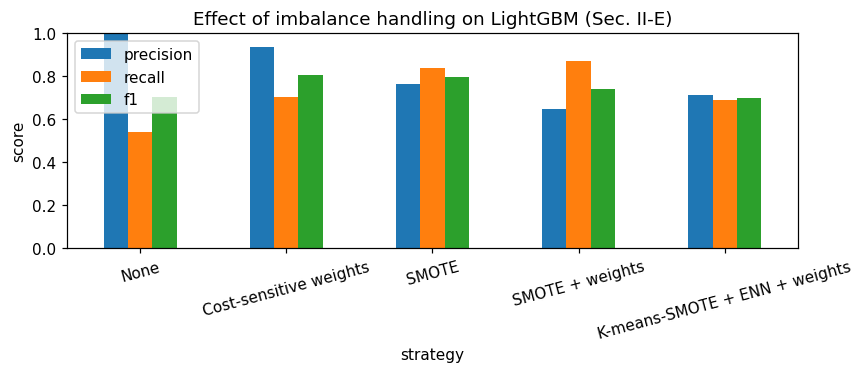

In [8]:
ax = imb_df[["precision", "recall", "f1"]].plot.bar(figsize=(8, 3.5), rot=15)
ax.set_ylim(0, 1); ax.set_ylabel("score"); ax.set_title("Effect of imbalance handling on LightGBM (Sec. II-E)")
plt.tight_layout(); plt.show()


## 4. Deep learning baselines (Sec. II-B, II-F)

Two DL approaches from the survey, kept small enough to run on CPU:

1. **MLP classifier** on the tabular feature vector (the row-wise deep model used in [1], [5]).
2. **Autoencoder anomaly detector** trained on *legitimate* transactions only; reconstruction error is the fraud score. This is the unsupervised route used in [11] and the zero-day approach in [23], since it needs no fraud labels at training time.


In [9]:
# 4a. Supervised MLP with a lightly resampled training set (the network has no class_weight option in sklearn)
sm = SMOTE(k_neighbors=k_nb, sampling_strategy=0.05, random_state=RNG)
X_mlp, y_mlp = sm.fit_resample(X_train, y_train)
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4, batch_size=256,
                    max_iter=40, early_stopping=True, random_state=RNG)
mlp.fit(X_mlp, y_mlp)
evaluate("MLP (64-32)", "Deep learning", mlp, X_test, y_test, "Low (black box)")


MLP (64-32)                  acc=0.9992 prec=0.792 rec=0.689 f1=0.737 auc=0.9494 aucpr=0.738 lat=0.08ms


array([1.24708110e-12, 4.33065892e-10, 1.98904325e-06, ...,
       1.05577447e-07, 5.73732729e-09, 1.02489822e-08], shape=(36000,))

Autoencoder (recon. error)   acc=0.9972 prec=0.280 rec=0.426 f1=0.338 auc=0.9957 aucpr=0.249 lat=0.10ms


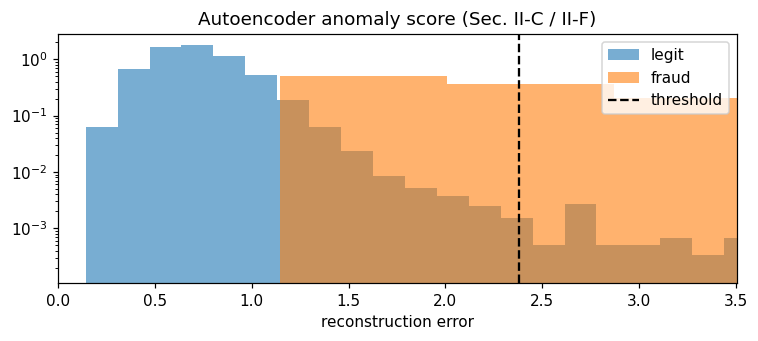

In [10]:
# 4b. Autoencoder on legitimate transactions only; score = reconstruction MSE
X_legit = X_train[y_train == 0]
ae = MLPRegressor(hidden_layer_sizes=(16, 8, 16), activation="tanh", max_iter=30,
                  batch_size=256, random_state=RNG, early_stopping=True)
ae.fit(X_legit, X_legit)

def recon_error(A):
    return ((ae.predict(A) - A) ** 2).mean(axis=1)

err_train_legit = recon_error(X_legit)
# Threshold: flag anything above the 99.8th percentile of legitimate error (approx. the base fraud rate, Table III)
ae_threshold = np.percentile(err_train_legit, 99.8)

err_test = recon_error(X_test)
p_ae = evaluate("Autoencoder (recon. error)", "Deep learning", ae, X_test, y_test,
                "Low (anomaly score only)", proba_fn=recon_error, threshold=ae_threshold)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(err_test[y_test == 0], bins=80, alpha=.6, label="legit", density=True)
ax.hist(err_test[y_test == 1], bins=80, alpha=.6, label="fraud", density=True)
ax.axvline(ae_threshold, color="k", ls="--", label="threshold")
ax.set_xlim(0, np.percentile(err_test, 99.9)); ax.set_yscale("log")
ax.set_xlabel("reconstruction error"); ax.legend(); ax.set_title("Autoencoder anomaly score (Sec. II-C / II-F)")
plt.tight_layout(); plt.show()


## 5. Explainable AI and the interpretability-latency trade-off (Sec. II-D, IV-B)

The survey reports that a bolted-on SHAP explainer adds ~30 ms per prediction, a meaningful fraction of a sub-100 ms authorisation budget. This section measures that directly on the LightGBM model:

- **TreeSHAP** (exact for tree ensembles, fast path)
- **KernelSHAP** (model-agnostic, the slow path the survey figure refers to)
- **LIME** (Almalki & Masud [13])

The point is not which explainer is "best", but the cost of adding explanation as a **second pass** — which motivates Layer 4 of the hybrid architecture.


In [11]:
import shap

lgb_model = boosted["LightGBM"]
feature_names = feature_cols
background = shap.sample(X_train, 100, random_state=RNG)
fraud_idx = np.where(y_test == 1)[0][:20]
sample_idx = np.concatenate([fraud_idx, np.where(y_test == 0)[0][:20]])
X_explain = X_test[sample_idx]

# --- TreeSHAP (fast path)
tree_expl = shap.TreeExplainer(lgb_model)
t0 = time.perf_counter()
for i in range(len(X_explain)):
    tree_expl.shap_values(X_explain[i:i+1])
tree_shap_ms = (time.perf_counter() - t0) / len(X_explain) * 1000

# --- KernelSHAP (model-agnostic; the expensive path)
kernel_expl = shap.KernelExplainer(lambda A: lgb_model.predict_proba(A)[:, 1], background)
n_kernel = 5
t0 = time.perf_counter()
for i in range(n_kernel):
    kernel_expl.shap_values(X_explain[i:i+1], nsamples=200, silent=True)
kernel_shap_ms = (time.perf_counter() - t0) / n_kernel * 1000

# --- LIME
try:
    from lime.lime_tabular import LimeTabularExplainer
    lime_expl = LimeTabularExplainer(X_train, feature_names=feature_names, class_names=["legit", "fraud"],
                                     discretize_continuous=True, random_state=RNG)
    t0 = time.perf_counter()
    for i in range(n_kernel):
        lime_expl.explain_instance(X_explain[i], lgb_model.predict_proba, num_features=8, num_samples=500)
    lime_ms = (time.perf_counter() - t0) / n_kernel * 1000
except ImportError:
    lime_ms = np.nan
    print("lime not installed (pip install lime); skipping LIME timing")

base_ms = [r for r in RESULTS if r["model"] == "LightGBM"][0]["latency_ms"]
xai_lat = pd.DataFrame({
    "stage": ["LightGBM inference only", "+ TreeSHAP", "+ KernelSHAP (200 samples)", "+ LIME (500 samples)"],
    "ms per transaction": [base_ms, base_ms + tree_shap_ms, base_ms + kernel_shap_ms, base_ms + lime_ms],
}).set_index("stage")
xai_lat.round(2)


lime not installed (pip install lime); skipping LIME timing


,ms per transaction
stage,
LightGBM inference only,0.62
+ TreeSHAP,2.81
+ KernelSHAP (200 samples),203.05
+ LIME (500 samples),NaN


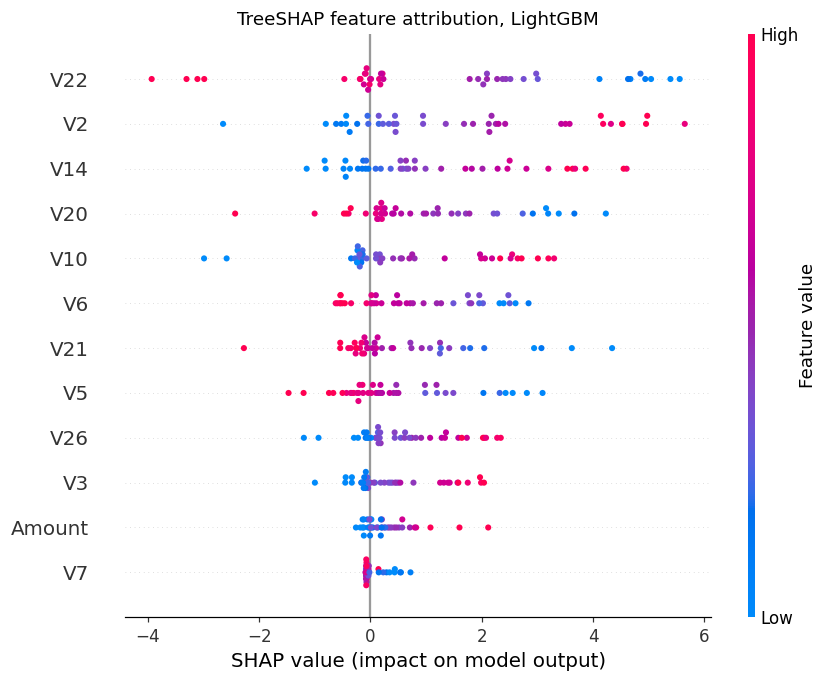

Transaction #998  true label = 1  p(fraud) = 0.947
V2     4.182
V14    2.804
V20    2.737
V3     2.041
V6     1.753
V26    1.642


In [12]:
# Global view: which PCA components drive the fraud score (Sec. II-D)
sv = tree_expl.shap_values(X_test[sample_idx])
if isinstance(sv, list):   # older shap returns [class0, class1]
    sv = sv[1]
shap.summary_plot(sv, X_test[sample_idx], feature_names=feature_names, max_display=12, show=False)
plt.title("TreeSHAP feature attribution, LightGBM"); plt.tight_layout(); plt.show()

# Local view for one fraud transaction: the per-prediction rationale a regulator asks for
i = 0
contrib = pd.Series(sv[i], index=feature_names).sort_values(key=np.abs, ascending=False).head(6)
print(f"Transaction #{sample_idx[i]}  true label = {y_test[sample_idx[i]]}  "
      f"p(fraud) = {lgb_model.predict_proba(X_explain[i:i+1])[0,1]:.3f}")
print(contrib.round(3).to_string())


## 6. Relational / graph check (Sec. II-C)

The PCA-anonymised dataset has no account, device or merchant identifiers, so a graph cannot be built from it directly. This section **simulates the entity layer** that a bank's own data would carry: each transaction is assigned an `account`, `device` and `merchant`, and fraud transactions are made to **share devices and mule accounts** (the ring signal described in [11], [12]).

The graph check then computes, for a transaction, how many *recently flagged* entities are within two hops of its account/device — the "device seen on three previously flagged accounts" reason code from Section V-D. This is a lightweight relational score, not a full GNN; a GNN (e.g. PyTorch Geometric GraphSAGE on this same graph) would slot into the same place.


In [13]:
def simulate_entities(n, y, n_accounts=None, n_devices=None, n_merchants=300, ring_size=6, seed=RNG):
    """Attach account / device / merchant ids. Fraud rows are grouped into rings that reuse devices and accounts."""
    rs = np.random.RandomState(seed)
    n_accounts = n_accounts or n // 4
    n_devices = n_devices or n // 5
    acct = rs.randint(0, n_accounts, n)
    dev = rs.randint(0, n_devices, n)
    merch = rs.randint(0, n_merchants, n)
    fraud_rows = np.where(y == 1)[0]
    rs.shuffle(fraud_rows)
    for r, start in enumerate(range(0, len(fraud_rows), ring_size)):
        ring = fraud_rows[start:start + ring_size]
        ring_devices = rs.randint(0, n_devices, 2)          # a ring shares 1-2 devices
        ring_accounts = rs.randint(0, n_accounts, 3)        # and a few mule accounts
        dev[ring] = rs.choice(ring_devices, len(ring))
        acct[ring] = rs.choice(ring_accounts, len(ring))
    return pd.DataFrame({"account": acct, "device": dev, "merchant": merch})

# Entities are assigned over the whole dataset *before* the split, so rings in the test period reuse
# devices and mule accounts that were already flagged in the training period, as they do in practice.
entities = simulate_entities(len(df), y, seed=1)
ent_train = entities.iloc[idx_train].reset_index(drop=True)
ent_test = entities.iloc[idx_test].reset_index(drop=True)

def build_graph(ent, flagged_mask):
    """Account--device entity graph. Merchants are high-degree hubs that would connect everything within
    two hops, so they are kept as node attributes rather than traversed. Flagged entities carry a flag count."""
    G = nx.Graph()
    for (a, d, m), f in zip(ent[["account", "device", "merchant"]].values, flagged_mask):
        a, d = f"acct:{a}", f"dev:{d}"
        for node in (a, d):
            if node not in G:
                G.add_node(node, flags=0, merchants=set())
            if f:
                G.nodes[node]["flags"] += 1
        G.nodes[a]["merchants"].add(m)
        G.add_edge(a, d)
    return G

# The "rolling transaction graph" is built from training-period transactions, using known fraud labels as flags
G = build_graph(ent_train, y_train == 1)
print(f"graph: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")

def ring_score(G, account, device, radius=2):
    """Number of previously flagged entities within `radius` hops of this transaction's account or device."""
    score, seen = 0, set()
    for node in (f"acct:{account}", f"dev:{device}"):
        if node not in G:
            continue
        for nb in nx.single_source_shortest_path_length(G, node, cutoff=radius):
            if nb not in seen:
                seen.add(nb)
                score += G.nodes[nb].get("flags", 0)
    return score

t0 = time.perf_counter()
ring_scores = np.array([ring_score(G, a, d) for a, d in ent_test[["account", "device"]].values])
graph_ms = (time.perf_counter() - t0) / len(ent_test) * 1000
print(f"graph check: {graph_ms:.3f} ms per transaction")
print("mean ring score  legit:", ring_scores[y_test == 0].mean().round(3), " fraud:", ring_scores[y_test == 1].mean().round(3))


graph: 51,434 nodes, 83,959 edges


graph check: 0.047 ms per transaction
mean ring score  legit: 0.232  fraud: 6.328


## 7. Four-layer hybrid pipeline (Sec. V, Fig. 3, Table II)

```
 all transactions
       │
 [L1] deterministic pre-filter ──► auto-approve (clear low risk) / auto-block (known-bad)
       │ ambiguous
 [L2] calibrated LightGBM score  ──► approve if p < τ_low
       │ p ≥ τ_low  (suspicious)
 [L3] relational graph check     ──► escalate to review if ring score high or p ≥ τ_high
       │
 [L4] native reason codes        ──► decision + human-readable rationale (no second explainer pass)
```

Escalation narrows at each stage, so the expensive layers run on a small fraction of volume. Layer 4 here uses LightGBM's built-in per-row contributions (`pred_contrib=True`), which are computed in the **same forward pass** as the score, rather than a separate SHAP call. That is the "native explanation" idea in Section V-D, implemented with the tools available for a tree model.


In [14]:
class HybridFraudPipeline:
    def __init__(self, model, graph, feature_names, tau_low=0.10, tau_high=0.80, ring_threshold=2,
                 amount_scaler=None, high_amount_z=6.0, known_bad_devices=()):
        self.model, self.graph, self.feature_names = model, graph, feature_names
        self.tau_low, self.tau_high, self.ring_threshold = tau_low, tau_high, ring_threshold
        self.high_amount_z = high_amount_z
        self.known_bad_devices = set(known_bad_devices)
        self.stats = dict(l1_block=0, l1_approve=0, l2_approve=0, l3_ring=0, l3_review=0, l4_approve=0)
        self.amount_col = feature_names.index("Amount")

    # ---- Layer 1: deterministic pre-filter (velocity / known-bad / clearly low risk)
    def layer1(self, x, ent):
        if ent["device"] in self.known_bad_devices:
            return "BLOCK", "L1: device on known-bad list"
        if x[self.amount_col] > self.high_amount_z:            # standardized Amount far above normal
            return None, None                                  # never auto-approve, send to L2
        if abs(x[self.amount_col]) < 0.05 and ent.get("recent_txn_count", 0) <= 1:
            return "APPROVE", "L1: low amount, no velocity signal"
        return None, None

    # ---- Layer 2 + 4: calibrated ensemble with native per-row contributions
    def layer2(self, x):
        raw = self.model.predict(x.reshape(1, -1), pred_contrib=True)[0]   # contributions + bias, one pass
        logit = raw.sum()
        p = 1 / (1 + np.exp(-logit))
        contrib = pd.Series(raw[:-1], index=self.feature_names)
        return p, contrib

    # ---- Layer 3: relational check
    def layer3(self, ent):
        return ring_score(self.graph, ent["account"], ent["device"])

    # ---- Layer 4: reason codes straight from the L2 contributions + L3 score
    @staticmethod
    def reason_codes(contrib, ring, top_k=3):
        top = contrib.sort_values(ascending=False).head(top_k)
        codes = [f"{f} pushes risk up ({v:+.2f})" for f, v in top.items() if v > 0]
        if ring >= 1:
            codes.append(f"linked to {ring} previously flagged entities within 2 hops")
        return codes

    def score(self, x, ent):
        d, why = self.layer1(x, ent)
        if d is not None:
            self.stats["l1_block" if d == "BLOCK" else "l1_approve"] += 1
            return dict(decision=d, p=None, ring=0, reasons=[why], layer=1)
        p, contrib = self.layer2(x)
        if p < self.tau_low:
            self.stats["l2_approve"] += 1
            return dict(decision="APPROVE", p=p, ring=0, reasons=["L2: score below review threshold"], layer=2)
        ring = self.layer3(ent)
        reasons = self.reason_codes(contrib, ring)
        if p >= self.tau_high or ring >= self.ring_threshold:
            self.stats["l3_review" if ring < self.ring_threshold else "l3_ring"] += 1
            return dict(decision="BLOCK", p=p, ring=ring, reasons=reasons, layer=3 if ring >= self.ring_threshold else 2)
        self.stats["l4_approve"] += 1
        return dict(decision="APPROVE", p=p, ring=ring, reasons=reasons + ["borderline; approved, logged for monitoring"], layer=4)

pipeline = HybridFraudPipeline(lgb_model.booster_, G, feature_names, tau_low=0.10, tau_high=0.80, ring_threshold=2)

t0 = time.perf_counter()
decisions = [pipeline.score(X_test[i], ent_test.iloc[i]) for i in range(len(X_test))]
pipe_ms = (time.perf_counter() - t0) / len(X_test) * 1000

pipe_pred = np.array([1 if d["decision"] == "BLOCK" else 0 for d in decisions])
print(f"hybrid pipeline: {pipe_ms:.3f} ms / transaction (end to end, incl. reason codes)")
print("stage counts:", pipeline.stats)
print(f"precision={precision_score(y_test, pipe_pred):.3f}  recall={recall_score(y_test, pipe_pred):.3f}  "
      f"f1={f1_score(y_test, pipe_pred):.3f}")
print(confusion_matrix(y_test, pipe_pred))


hybrid pipeline: 2.356 ms / transaction (end to end, incl. reason codes)
stage counts: {'l1_block': 0, 'l1_approve': 1741, 'l2_approve': 34189, 'l3_ring': 48, 'l3_review': 4, 'l4_approve': 18}
precision=1.000  recall=0.852  f1=0.920
[[35939     0]
 [    9    52]]


In [15]:
# Example audit record for a blocked transaction: this is the artefact SR 11-7-style review asks for (Sec. IV-C, V-D)
blocked = [i for i, d in enumerate(decisions) if d["decision"] == "BLOCK" and y_test[i] == 1][:3]
for i in blocked:
    d = decisions[i]
    print(f"txn #{i:<6} decision={d['decision']}  p={d['p']:.3f}  ring={d['ring']}  decided at layer {d['layer']}")
    for r in d["reasons"]:
        print("   -", r)


txn #998    decision=BLOCK  p=0.947  ring=8  decided at layer 3
   - V2 pushes risk up (+4.18)
   - V14 pushes risk up (+2.80)
   - V20 pushes risk up (+2.74)
   - linked to 8 previously flagged entities within 2 hops
txn #1159   decision=BLOCK  p=0.987  ring=4  decided at layer 3
   - V22 pushes risk up (+4.67)
   - V2 pushes risk up (+4.32)
   - V10 pushes risk up (+2.65)
   - linked to 4 previously flagged entities within 2 hops
txn #2680   decision=BLOCK  p=0.990  ring=6  decided at layer 3
   - V6 pushes risk up (+2.50)
   - V10 pushes risk up (+2.33)
   - V2 pushes risk up (+2.30)
   - linked to 6 previously flagged entities within 2 hops


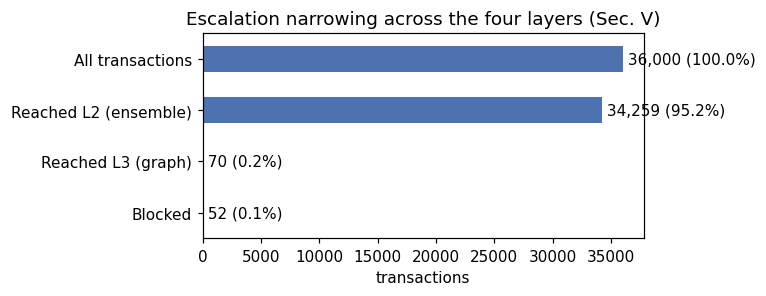

In [16]:
# Escalation funnel (Fig. 3): how much volume reaches each layer
s = pipeline.stats
funnel = pd.Series({
    "All transactions": len(X_test),
    "Reached L2 (ensemble)": len(X_test) - s["l1_block"] - s["l1_approve"],
    "Reached L3 (graph)": s["l3_ring"] + s["l3_review"] + s["l4_approve"],
    "Blocked": s["l1_block"] + s["l3_ring"] + s["l3_review"],
})
ax = funnel.plot.barh(figsize=(7, 2.8), color="#4c72b0")
ax.invert_yaxis(); ax.set_xlabel("transactions")
for i, v in enumerate(funnel.values):
    ax.text(v, i, f" {v:,} ({v/len(X_test):.1%})", va="center")
ax.set_title("Escalation narrowing across the four layers (Sec. V)"); plt.tight_layout(); plt.show()


## 7b. Proposed enhancement: Relational-Anomaly Augmented Boosting (RAAB)

The four-layer pipeline uses the relational signal (Layer 3) and, in the survey's zero-day papers, an unsupervised novelty signal, only **after** the scoring model has made its decision. RAAB moves both signals **into** the scoring model as features, so one boosted model sees them jointly and the native reason codes can name them:

1. **Entity-risk features** (4): the device's and account's prior flag rate, and the count and rate of flags within two hops in the rolling account-device graph. On training rows these are computed **out-of-fold** (a row never sees its own label); on test rows they come from the training-period graph only. This is what makes them time-respecting rather than leaky.
2. **Autoencoder residual features** (30): mean and max reconstruction error plus the per-feature squared residuals from the legitimate-only autoencoder of Section 4. These carry a novelty signal that needs no fraud labels.

**Zero-day protocol.** To test the claim the survey says nobody tests, the synthetic generator is extended with a second fraud pattern ("B") that shifts a *disjoint* set of PCA dimensions and appears **only in the test period**. The row model has never seen a B transaction. The ablation below reports recall on B separately.


In [17]:
def make_zero_day(n=120_000, fraud_rate=0.0017, n_pca=28, zero_day_frac=0.3, seed=RNG):
    """Known pattern A everywhere; pattern B (disjoint shifted dims) only in the test period."""
    rs = np.random.RandomState(seed); nf = int(n * fraud_rate); nl = n - nf
    legit = rs.normal(0, 1, (nl, n_pca))
    nB = int(nf * zero_day_frac); nA = nf - nB
    fa = rs.normal(0, 1.5, (nA, n_pca)); dA = rs.choice(n_pca, 10, replace=False)
    fa[:, dA] += rs.uniform(1.0, 2.2, len(dA)) * rs.choice([-1, 1], len(dA))
    fb = rs.normal(0, 1.5, (nB, n_pca)); dB = rs.choice(np.setdiff1d(np.arange(n_pca), dA), 10, replace=False)
    fb[:, dB] += rs.uniform(1.0, 2.2, len(dB)) * rs.choice([-1, 1], len(dB))
    Xz = np.vstack([legit, fa, fb]); yz = np.r_[np.zeros(nl), np.ones(nA), np.ones(nB)].astype(int)
    pattern = np.r_[np.full(nl, "legit"), np.full(nA, "A"), np.full(nB, "B")]
    d = pd.DataFrame(Xz, columns=[f"V{i}" for i in range(1, n_pca + 1)])
    d.insert(0, "Time", rs.uniform(0, 172_800, n)); d["Amount"] = np.r_[rs.lognormal(3, 1, nl), rs.lognormal(4, 1.4, nf)]
    d["Class"] = yz; d["pattern"] = pattern
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

def zero_day_split(d, seed=RNG):
    yz, pat = d["Class"].values, d["pattern"].values
    idxB = np.where(pat == "B")[0]; rest = np.where(pat != "B")[0]
    tr, te = train_test_split(rest, test_size=0.3, stratify=yz[rest], random_state=seed)
    te = np.concatenate([te, idxB])                      # every zero-day row lands in test
    Xz = d[[c for c in d.columns if c not in ("Class", "pattern")]].copy()
    sc = StandardScaler().fit(Xz.iloc[tr][["Time", "Amount"]]); Xz[["Time", "Amount"]] = sc.transform(Xz[["Time", "Amount"]])
    Xz = Xz.values
    return Xz[tr], Xz[te], yz[tr], yz[te], pat[te], tr, te


In [18]:
def build_risk_graph(ent, flagged):
    """Account-device graph with per-node transaction count and flag count."""
    Gr = nx.Graph()
    for (a, d), f in zip(ent[["account", "device"]].values, flagged):
        a, d = f"acct:{a}", f"dev:{d}"
        for node in (a, d):
            if node not in Gr: Gr.add_node(node, flags=0, n=0)
            Gr.nodes[node]["n"] += 1; Gr.nodes[node]["flags"] += int(f)
        Gr.add_edge(a, d)
    return Gr

def entity_risk_feats(Gr, ent):
    """4 features: device prior flag rate, account prior flag rate, 2-hop flag count, 2-hop flag rate."""
    out = np.zeros((len(ent), 4))
    for i, (a, d) in enumerate(ent[["account", "device"]].values):
        a, d = f"acct:{a}", f"dev:{d}"
        nd = Gr.nodes[d] if d in Gr else {"flags": 0, "n": 0}; na = Gr.nodes[a] if a in Gr else {"flags": 0, "n": 0}
        out[i, 0] = nd["flags"] / (nd["n"] + 1); out[i, 1] = na["flags"] / (na["n"] + 1)
        seen, fl, nn = set(), 0, 0
        for node in (a, d):
            if node not in Gr: continue
            for nb in nx.single_source_shortest_path_length(Gr, node, cutoff=2):
                if nb in seen: continue
                seen.add(nb); fl += Gr.nodes[nb]["flags"]; nn += Gr.nodes[nb]["n"]
        out[i, 2] = fl; out[i, 3] = fl / (nn + 1)
    return out

def oof_entity_feats(ent_tr, ytr_, ent_te, n_folds=5, seed=RNG):
    """Out-of-fold on train (no row sees its own label); full training graph for test."""
    from sklearn.model_selection import StratifiedKFold
    Etr = np.zeros((len(ent_tr), 4))
    for f_tr, f_ho in StratifiedKFold(n_folds, shuffle=True, random_state=seed).split(np.zeros(len(ytr_)), ytr_):
        Etr[f_ho] = entity_risk_feats(build_risk_graph(ent_tr.iloc[f_tr], ytr_[f_tr] == 1), ent_tr.iloc[f_ho])
    Gfull = build_risk_graph(ent_tr, ytr_ == 1)
    return Etr, entity_risk_feats(Gfull, ent_te), Gfull

def fit_ae_feats(Xtr_, ytr_, seed=RNG):
    """Legit-only autoencoder; returns a function giving [mse, max|r|, r_1^2 .. r_d^2]."""
    ae_ = MLPRegressor(hidden_layer_sizes=(16, 8, 16), activation="tanh", max_iter=30, batch_size=256,
                       random_state=seed, early_stopping=True).fit(Xtr_[ytr_ == 0], Xtr_[ytr_ == 0])
    def feats(A):
        R = ae_.predict(A) - A
        return np.hstack([(R ** 2).mean(1, keepdims=True), np.abs(R).max(1, keepdims=True), R ** 2])
    return feats, ae_


In [19]:
from sklearn.metrics import precision_recall_curve

def raab_lgbm(pw_):
    return lgb.LGBMClassifier(n_estimators=400, num_leaves=31, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                              scale_pos_weight=min(pw_, 50), reg_lambda=5.0, min_child_samples=50, max_delta_step=1.0,
                              n_jobs=-1, random_state=RNG, verbose=-1)

def run_raab(seed):
    dz = make_zero_day(seed=seed)
    Xtr_, Xte_, ytr_, yte_, pat_te, tr, te = zero_day_split(dz, seed=seed)
    ent_z = simulate_entities(len(dz), dz["Class"].values, seed=seed)
    Etr, Ete, Gfull = oof_entity_feats(ent_z.iloc[tr].reset_index(drop=True), ytr_, ent_z.iloc[te].reset_index(drop=True), seed=seed)
    ae_feats, _ = fit_ae_feats(Xtr_, ytr_, seed=seed); Atr, Ate = ae_feats(Xtr_), ae_feats(Xte_)
    pw_ = (ytr_ == 0).sum() / (ytr_ == 1).sum()
    variants = {"LightGBM (base)": (Xtr_, Xte_),
                "+ AE residual feats": (np.hstack([Xtr_, Atr]), np.hstack([Xte_, Ate])),
                "+ entity-risk feats": (np.hstack([Xtr_, Etr]), np.hstack([Xte_, Ete])),
                "RAAB (+ both)": (np.hstack([Xtr_, Atr, Etr]), np.hstack([Xte_, Ate, Ete]))}
    rows, models = [], {}
    for name, (A, B) in variants.items():
        m = raab_lgbm(pw_).fit(A, ytr_); p = m.predict_proba(B)[:, 1]; pred = (p >= 0.5).astype(int)
        pr, rc, _ = precision_recall_curve(yte_, p)
        rows.append(dict(model=name, seed=seed, precision=precision_score(yte_, pred, zero_division=0), recall=recall_score(yte_, pred),
                         f1=f1_score(yte_, pred), auc_pr=average_precision_score(yte_, p),
                         recall_known=recall_score(yte_[pat_te != "B"], pred[pat_te != "B"]),
                         recall_zero_day=pred[pat_te == "B"].mean(), recall_at_p99=rc[pr >= 0.99].max() if (pr >= 0.99).any() else 0.0))
        models[name] = (m, p)
    return pd.DataFrame(rows), dict(models=models, Xte=Xte_, yte=yte_, pat_te=pat_te, Ate=Ate, Ete=Ete, ae_feats=ae_feats, Gfull=Gfull, ent_te=ent_z.iloc[te].reset_index(drop=True))

N_SEEDS = 3          # ~1 min per seed on CPU
raab_runs, raab_ctx = [], None
for sd in [RNG, 7, 2024][:N_SEEDS]:
    r, ctx = run_raab(sd); raab_runs.append(r)
    if raab_ctx is None: raab_ctx = ctx
raab_all = pd.concat(raab_runs)
raab_summary = raab_all.groupby("model", sort=False)[["precision", "recall", "f1", "auc_pr", "recall_known", "recall_zero_day", "recall_at_p99"]].agg(["mean", "std"])
raab_summary.round(3)


precision        recall            f1        auc_pr  \
                         mean    std   mean    std   mean    std   mean   
model                                                                     
LightGBM (base)         0.937  0.031  0.285  0.011  0.437  0.016  0.411   
+ AE residual feats     0.917  0.050  0.375  0.010  0.532  0.005  0.629   
+ entity-risk feats     0.976  0.024  0.388  0.015  0.555  0.019  0.665   
RAAB (+ both)           0.975  0.023  0.619  0.006  0.757  0.011  0.905   

                           recall_known        recall_zero_day         \
                       std         mean    std            mean    std   
model                                                                   
LightGBM (base)      0.029        0.690  0.027           0.000  0.000   
+ AE residual feats  0.005        0.814  0.040           0.066  0.033   
+ entity-risk feats  0.034        0.860  0.040           0.055  0.034   
RAAB (+ both)        0.023        0.876  0.027           0.437  0.025   

                    recall_at_p99         
                             mean    std  
model                                     
LightGBM (base)             0.202  0.025  
+ AE residual feats         0.263  0.065  
+ entity-risk feats         0.365  0.073  
RAAB (+ both)               0.506  0.153

In [20]:
# Per-transaction latency of the full RAAB feature path (AE forward + entity-risk lookup + LightGBM with native contributions)
m_raab, _ = raab_ctx["models"]["RAAB (+ both)"]; Xte_ = raab_ctx["Xte"]; ent_te_ = raab_ctx["ent_te"]; Gfull = raab_ctx["Gfull"]
idx = np.random.RandomState(0).choice(len(Xte_), 300, replace=False)
t0 = time.perf_counter()
for i in idx:
    x = Xte_[i:i+1]; a = raab_ctx["ae_feats"](x); e = entity_risk_feats(Gfull, ent_te_.iloc[[i]])
    m_raab.booster_.predict(np.hstack([x, a, e]), pred_contrib=True)
raab_ms = (time.perf_counter() - t0) / len(idx) * 1000
print(f"RAAB end-to-end (features + score + native contributions): {raab_ms:.2f} ms / transaction")

# Native reason codes now include the injected signals
raab_names = feature_cols + ["ae_mse", "ae_max_resid"] + [f"ae_r2_{c}" for c in feature_cols] + ["dev_flag_rate", "acct_flag_rate", "hop2_flags", "hop2_flag_rate"]
zb = np.where((raab_ctx["pat_te"] == "B") & (raab_ctx["models"]["RAAB (+ both)"][1] >= 0.5))[0][:2]
for i in zb:
    contrib = m_raab.booster_.predict(np.hstack([Xte_[i:i+1], raab_ctx["Ate"][i:i+1], raab_ctx["Ete"][i:i+1]]), pred_contrib=True)[0][:-1]
    top = pd.Series(contrib, index=raab_names).sort_values(ascending=False).head(4)
    print(f"zero-day txn #{i}: " + "; ".join(f"{k} {v:+.2f}" for k, v in top.items()))


RAAB end-to-end (features + score + native contributions): 2.76 ms / transaction
zero-day txn #35983: ae_mse +9.03; dev_flag_rate +2.98; V16 +2.33; hop2_flag_rate +1.45
zero-day txn #35985: ae_mse +8.89; hop2_flag_rate +2.11; hop2_flags +1.67; V13 +1.65


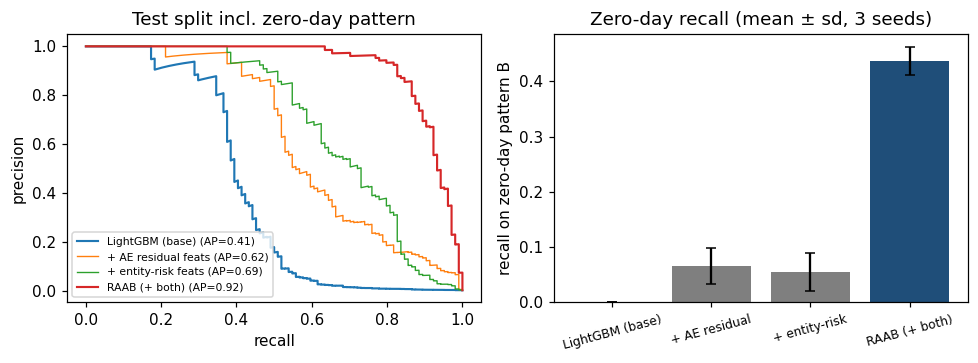

In [21]:
# Figure: PR curves (base vs RAAB) and zero-day recall by variant, first seed
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
yte_, pat_te = raab_ctx["yte"], raab_ctx["pat_te"]
for name, (m, p) in raab_ctx["models"].items():
    pr, rc, _ = precision_recall_curve(yte_, p); ax1.plot(rc, pr, lw=1.4 if "RAAB" in name or "base" in name else 0.9, label=f"{name} (AP={average_precision_score(yte_, p):.2f})")
ax1.set_xlabel("recall"); ax1.set_ylabel("precision"); ax1.set_title("Test split incl. zero-day pattern"); ax1.legend(fontsize=7, loc="lower left")
zd = raab_summary[("recall_zero_day", "mean")]; zs = raab_summary[("recall_zero_day", "std")].fillna(0)
ax2.bar(range(len(zd)), zd.values, yerr=zs.values, color=["#7f7f7f", "#7f7f7f", "#7f7f7f", "#1f4e79"], capsize=3)
ax2.set_xticks(range(len(zd))); ax2.set_xticklabels([s.replace(" feats", "") for s in zd.index], rotation=15, fontsize=8)
ax2.set_ylabel("recall on zero-day pattern B"); ax2.set_title(f"Zero-day recall (mean ± sd, {N_SEEDS} seeds)")
plt.tight_layout(); plt.show()


## 8. Comparison framework (Sec. IV, Table I, Fig. 2)

All models scored on the same held-out split, with single-transaction latency measured in the same way. Add the hybrid pipeline as a row so it can be compared on equal footing — the "common present-day evaluation harness" the paper's conclusion calls for.


In [22]:
RESULTS.append(dict(model="Hybrid 4-layer pipeline", family="Streaming / hybrid",
                    accuracy=accuracy_score(y_test, pipe_pred), precision=precision_score(y_test, pipe_pred),
                    recall=recall_score(y_test, pipe_pred), f1=f1_score(y_test, pipe_pred),
                    auc_roc=np.nan, auc_pr=np.nan, latency_ms=pipe_ms, interpretability="High (native reason codes)"))

table = pd.DataFrame(RESULTS).set_index("model")
table.round(4)


,family,accuracy,precision,recall,f1,auc_roc,auc_pr,latency_ms,interpretability
model,,,,,,,,,
Logistic Regression,Classical ML,0.9967,0.3333,0.9508,0.4936,0.9980,0.9173,0.1629,High (intrinsic)
Random Forest,Classical ML,0.9989,1.0000,0.3279,0.4938,0.9969,0.7181,53.8303,Medium (feature importance)
KNN (k=5),Classical ML,0.9984,1.0000,0.0492,0.0938,0.6557,0.3126,4.0448,Low
Linear SVM (calib.),Classical ML,0.9997,1.0000,0.8033,0.8909,0.9978,0.9268,1.3142,Medium (linear weights)
XGBoost,Boosted ensemble,0.9995,0.9388,0.7541,0.8364,0.9996,0.9141,0.4211,Low-Medium (needs post-hoc XAI)
LightGBM,Boosted ensemble,0.9995,0.9375,0.7377,0.8257,0.9989,0.9115,0.6184,Low-Medium (needs post-hoc XAI)
MLP (64-32),Deep learning,0.9992,0.7925,0.6885,0.7368,0.9494,0.7377,0.0794,Low (black box)
Autoencoder (recon. error),Deep learning,0.9972,0.2796,0.4262,0.3377,0.9957,0.2485,0.1020,Low (anomaly score only)
Hybrid 4-layer pipeline,Streaming / hybrid,0.9998,1.0000,0.8525,0.9204,NaN,NaN,2.3556,High (native reason codes)


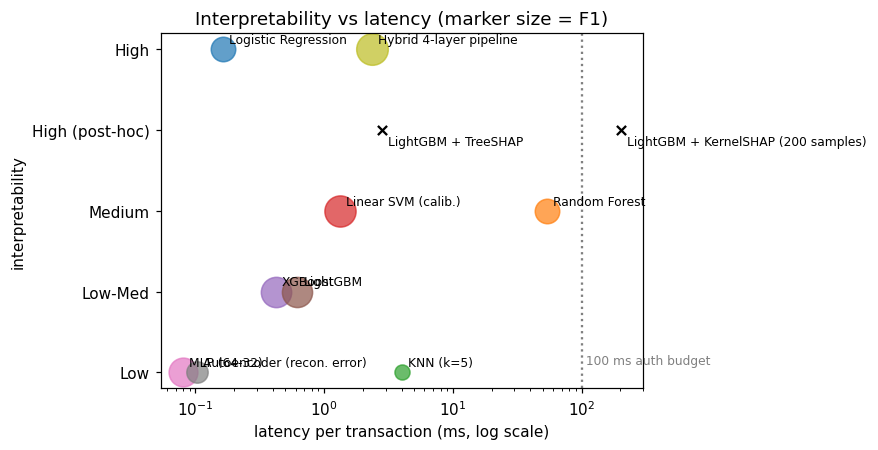

In [23]:
# Fig. 2 analogue: interpretability vs latency, marker size = F1
interp_rank = {"High (intrinsic)": 3, "High (native reason codes)": 3, "High (post-hoc)": 2.5,
               "Medium (feature importance)": 2, "Medium (linear weights)": 2,
               "Low-Medium (needs post-hoc XAI)": 1.5, "Low": 1, "Low (black box)": 1, "Low (anomaly score only)": 1}
fig, ax = plt.subplots(figsize=(8, 4.2))
for _, r in table.iterrows():
    ax.scatter(r["latency_ms"], interp_rank.get(r["interpretability"], 1), s=60 + 400 * (r["f1"] if pd.notna(r["f1"]) else 0),
               alpha=.7)
    ax.annotate(r.name, (r["latency_ms"], interp_rank.get(r["interpretability"], 1)), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
# Also plot the bolted-on explainer costs from Section 5
for stage, ms in xai_lat["ms per transaction"].items():
    if "+" in stage and pd.notna(ms):
        ax.scatter(ms, 2.5, marker="x", color="k")
        ax.annotate("LightGBM " + stage, (ms, 2.5), fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("latency per transaction (ms, log scale)")
ax.set_yticks([1, 1.5, 2, 2.5, 3]); ax.set_yticklabels(["Low", "Low-Med", "Medium", "High (post-hoc)", "High"])
ax.set_ylabel("interpretability"); ax.set_title("Interpretability vs latency (marker size = F1)")
ax.axvline(100, ls=":", color="gray"); ax.text(100, 1.05, " 100 ms auth budget", fontsize=8, color="gray")
plt.tight_layout(); plt.show()


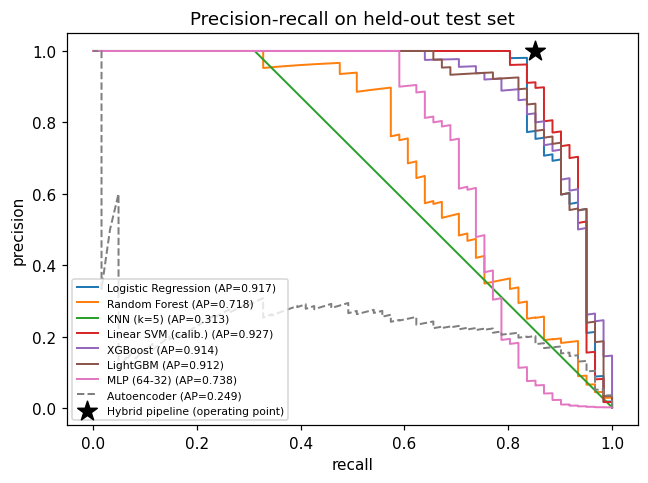

In [24]:
# Precision-recall curves: the appropriate view for a 0.17%-positive problem (accuracy is misleading, Sec. I)
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, m in {**classical, **boosted, "MLP (64-32)": mlp}.items():
    p = m.predict_proba(X_test)[:, 1]
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax.plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})", lw=1.3)
pr, rc, _ = precision_recall_curve(y_test, err_test)
ax.plot(rc, pr, "--", label=f"Autoencoder (AP={average_precision_score(y_test, err_test):.3f})", lw=1.3)
ax.scatter([recall_score(y_test, pipe_pred)], [precision_score(y_test, pipe_pred)], marker="*", s=180, color="k",
           zorder=5, label="Hybrid pipeline (operating point)")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall on held-out test set")
ax.legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()


## 9. Notes and next steps

- **Data source.** The cell in Section 1 prints whether the run used the real dataset or the synthetic stand-in. Only report numbers from the real dataset. On IEEE-CIS, replace the loader and the `feature_cols` list; everything downstream is schema-agnostic apart from the `Amount` reference in Layer 1.
- **Graph layer.** The entity graph is simulated because the public dataset is anonymised. With real account/device/merchant columns, drop `simulate_entities` and pass the true ids to `build_graph`. To upgrade the relational check to a GNN, train a GraphSAGE or heterogeneous GAT on `G` (PyTorch Geometric) and use its node embedding for the escalated account in place of `ring_score`.
- **Native explanation.** `pred_contrib=True` gives exact per-row contributions for a tree model in one pass. For a neural scoring head, the equivalent is a jointly trained attention or attribution head, as Section V-D describes.
- **Label delay and drift.** The pipeline's thresholds (`tau_low`, `tau_high`) are static. Reference [21] proposes a dynamic threshold manager under delayed labels; that would wrap `HybridFraudPipeline.score` with a rolling precision/recall estimate.
- **Federated training.** Not implemented here. Flower or FedML can train the Layer-2 LightGBM/XGBoost model across partitions without centralising raw rows, as in [16].
